In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
X,y=make_regression(n_samples=1500,n_features=4,n_informative=4,noise=15,bias=50,random_state=7)
df=pd.DataFrame(X,columns=['f1','f2','f3','f4'])
df['target']=y
print(df.shape)
df.describe().round(2)

(1500, 5)


,f1,f2,f3,f4,target
count,1500.00,1500.00,1500.00,1500.00,1500.00
mean,-0.05,0.02,-0.02,-0.02,47.57
std,1.00,1.00,0.99,0.99,56.60
min,-3.42,-3.08,-3.53,-3.26,-152.14
25%,-0.68,-0.64,-0.67,-0.68,7.97
50%,0.00,0.01,-0.02,0.02,48.05
75%,0.65,0.70,0.63,0.64,87.15
max,3.56,3.74,3.01,3.42,242.87


In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=7)
model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

In [4]:
r2_score(y_test,y_pred)

0.9270797499282479

In [5]:
print('MAE :',mean_absolute_error(y_test,y_pred))
print('RMSE:',np.sqrt(mean_squared_error(y_test,y_pred)))
print('Intercept:',model.intercept_)
print('Coefficients:',{n:round(float(c),2) for n,c in zip(['f1','f2','f3','f4'],model.coef_)})

MAE : 11.680366543340693
RMSE: 14.533757344797438
Intercept: 49.15494317746086
Coefficients: {'f1': 32.5, 'f2': 28.64, 'f3': 24.84, 'f4': 19.62}


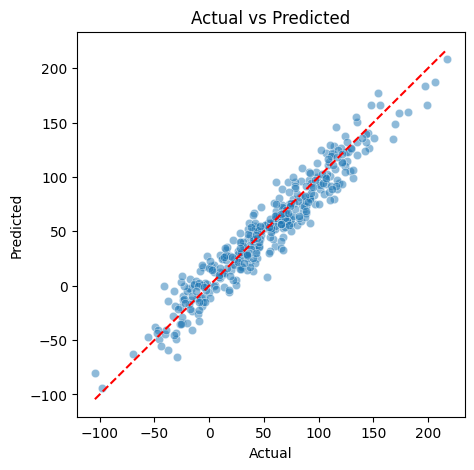

In [6]:
plt.figure(figsize=(5,5))
sns.scatterplot(x=y_test,y=y_pred,alpha=0.5)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--')
plt.title("Actual vs Predicted")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [7]:
new_sample=np.array([[1.5,-0.9,0.5,1.4],[-1.3,1.0,-1.2,-0.8],[0.2,0.1,0.0,0.3]],ndmin=2)
new_value=model.predict(new_sample)
print(f'the predicted values are {new_value.round(2)}')

the predicted values are [112.01  -9.96  64.4 ]
